IMPORT 문

In [135]:
# ============================================================
# 라이브러리
# ============================================================

import os
import xml.etree.ElementTree as ET
from pathlib import Path

import numpy as np
import pandas as pd
import requests

from dotenv import load_dotenv
from sklearn.neighbors import BallTree

import matplotlib.pyplot as plt


# ============================================================
# 기본 설정
# ============================================================

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

load_dotenv()

True

In [136]:
# ============================================================
# 경로 설정
# ============================================================

# 현재 노트북 위치:
# Apartment price/notebook/v2_5year_notebook/eda
PROJECT_DIR = Path.cwd().parents[2]

DATA_ROOT = PROJECT_DIR / "data"
DATA_DIR = DATA_ROOT / "v2_5year_seoul"

PROCESSED_DIR = DATA_DIR / "processed"
EXTERNAL_DIR = DATA_ROOT / "external"

DF_FE_BASE_PATH = (
    PROCESSED_DIR / "df_fe_base.parquet"
)

LIVING_FEATURE_PATH = (
    PROCESSED_DIR / "df_fe_living.parquet"
)

print("PROJECT_DIR:", PROJECT_DIR.resolve())
print("DF_FE_BASE_PATH:", DF_FE_BASE_PATH.resolve())

PROJECT_DIR: C:\Users\UK\Apartment price
DF_FE_BASE_PATH: C:\Users\UK\Apartment price\data\v2_5year_seoul\processed\df_fe_base.parquet


In [137]:
# ============================================================
# API 키 설정
# ============================================================

EMERGENCY_API_KEY = os.environ.get(
    "EMERGENCY_API_KEY",
    ""
)
KAKAO_REST_API_KEY = os.environ.get('KAKAO_REST_API_KEY')
if not EMERGENCY_API_KEY:
    raise ValueError(
        "EMERGENCY_API_KEY가 .env 파일에 설정되지 않았습니다."
    )

print("응급의료 API 키 로드 완료")

응급의료 API 키 로드 완료


In [138]:
load_dotenv()

EMERGENCY_API_KEY = os.environ.get(
    "EMERGENCY_API_KEY",
    ""
)

if not EMERGENCY_API_KEY:
    raise ValueError(
        "EMERGENCY_API_KEY가 .env 파일에 설정되지 않았습니다."
    )

print("API 키 로드 완료")

API 키 로드 완료


In [139]:
# ============================================================
# 응급의료기관 API 설정
# ============================================================

EMERGENCY_API_KEY = os.environ.get(
    "EMERGENCY_API_KEY",
    ""
)

if not EMERGENCY_API_KEY:
    raise ValueError(
        "EMERGENCY_API_KEY가 .env 파일에 설정되지 않았습니다."
    )

HOSPITAL_API_URL = (
    "https://apis.data.go.kr/"
    "B552657/ErmctInfoInqireService/"
    "getEgytListInfoInqire"
)

print("응급의료기관 API 설정 완료")

응급의료기관 API 설정 완료


# 병원 데이터

## 데이터 호출

In [140]:
# ============================================================
# 서울 전체 응급의료기관 수집
# ============================================================

params = {
    "serviceKey": EMERGENCY_API_KEY,
    "Q0": "서울특별시",
    "pageNo": 1,
    "numOfRows": 1000,
}

response = requests.get(
    HOSPITAL_API_URL,
    params=params,
    timeout=30,
)

response.raise_for_status()

root = ET.fromstring(response.content)

result_code = root.findtext(".//resultCode")
result_message = root.findtext(".//resultMsg")
total_count = int(
    root.findtext(".//totalCount", default="0")
)

print("응답 코드:", result_code)
print("응답 메시지:", result_message)
print("전체 기관 수:", total_count)

응답 코드: 00
응답 메시지: NORMAL SERVICE.
전체 기관 수: 74


In [141]:
# ============================================================
# 응급의료기관 응답 → DataFrame 변환
# ============================================================

hospital_records = []

for item in root.findall(".//item"):
    hospital_records.append({
        "병원ID": item.findtext("hpid"),
        "병원명": item.findtext("dutyName"),
        "주소": item.findtext("dutyAddr"),
        "대표전화": item.findtext("dutyTel1"),
        "응급실전화": item.findtext("dutyTel3"),
        "응급의료기관코드": item.findtext("dutyEmcls"),
        "응급의료기관분류": item.findtext("dutyEmclsName"),
        "위도": item.findtext("wgs84Lat"),
        "경도": item.findtext("wgs84Lon"),
    })

hospital_df = pd.DataFrame(hospital_records)

print("API 전체 기관 수:", total_count)
print("DataFrame 행 수:", len(hospital_df))
print("shape:", hospital_df.shape)

display(hospital_df.head())

API 전체 기관 수: 74
DataFrame 행 수: 74
shape: (74, 9)


,병원ID,병원명,주소,대표전화,응급실전화,응급의료기관코드,응급의료기관분류,위도,경도
0,A1100011,가톨릭대학교여의도성모병원,"서울특별시 영등포구 63로 10, 여의도성모병원 (여의도동)",02-1661-7575,02-3779-1199,G006,지역응급의료센터,37.51827233800711,126.93673129599131
1,A1121013,가톨릭대학교은평성모병원,서울특별시 은평구 통일로 1021 (진관동),02-1811-7755,02-1811-7755,G006,지역응급의료센터,37.633608409726854,126.91615048739686
2,A1100047,강남고려병원,서울특별시 관악구 관악로 242 (봉천동),1661-8267,02-874-7227,G009,응급실운영신고기관,37.4856188363947,126.956781703053
3,A1100141,강남베드로병원,"서울특별시 강남구 남부순환로 2649, 베드로병원 (도곡동)",1544-7522,1544-7522,G009,응급실운영신고기관,37.485612179925724,127.0395873429168
4,A1100076,강남힐병원,"서울특별시 관악구 남부순환로 1449, 강남힐병원 (신림동)",02-853-4600,02-853-9100,G009,응급실운영신고기관,37.4816513439454,126.911648078471


In [142]:
print(
    hospital_df["응급의료기관분류"]
    .value_counts(dropna=False)
)

응급의료기관분류
지역응급의료센터     24
응급실운영신고기관    23
지역응급의료기관     20
권역응급의료센터      7
Name: count, dtype: int64


### 데이터 정제

In [143]:
# ============================================================
# 응급의료기관 원본 데이터 확인
# ============================================================

print("데이터 크기:", hospital_df.shape)
print("\n컬럼:")
print(hospital_df.columns.tolist())

hospital_df.head()

데이터 크기: (74, 9)

컬럼:
['병원ID', '병원명', '주소', '대표전화', '응급실전화', '응급의료기관코드', '응급의료기관분류', '위도', '경도']


,병원ID,병원명,주소,대표전화,응급실전화,응급의료기관코드,응급의료기관분류,위도,경도
0,A1100011,가톨릭대학교여의도성모병원,"서울특별시 영등포구 63로 10, 여의도성모병원 (여의도동)",02-1661-7575,02-3779-1199,G006,지역응급의료센터,37.51827233800711,126.93673129599131
1,A1121013,가톨릭대학교은평성모병원,서울특별시 은평구 통일로 1021 (진관동),02-1811-7755,02-1811-7755,G006,지역응급의료센터,37.633608409726854,126.91615048739686
2,A1100047,강남고려병원,서울특별시 관악구 관악로 242 (봉천동),1661-8267,02-874-7227,G009,응급실운영신고기관,37.4856188363947,126.956781703053
3,A1100141,강남베드로병원,"서울특별시 강남구 남부순환로 2649, 베드로병원 (도곡동)",1544-7522,1544-7522,G009,응급실운영신고기관,37.485612179925724,127.0395873429168
4,A1100076,강남힐병원,"서울특별시 관악구 남부순환로 1449, 강남힐병원 (신림동)",02-853-4600,02-853-9100,G009,응급실운영신고기관,37.4816513439454,126.911648078471


In [144]:
# ============================================================
# 응급의료기관 데이터 정제
# ============================================================

hospital_clean = hospital_df[
    [
        "병원ID",
        "병원명",
        "응급의료기관코드",
        "응급의료기관분류",
        "주소",
        "위도",
        "경도",
    ]
].copy()

hospital_clean["위도"] = pd.to_numeric(
    hospital_clean["위도"],
    errors="coerce",
)

hospital_clean["경도"] = pd.to_numeric(
    hospital_clean["경도"],
    errors="coerce",
)

hospital_clean = (
    hospital_clean
    .drop_duplicates(
        subset="병원ID",
        keep="last",
    )
    .reset_index(drop=True)
)

print("정제 후 병원 수:", len(hospital_clean))

정제 후 병원 수: 74


In [145]:
# ============================================================
# 결측치 검증
# ============================================================

check_cols = [
    "병원ID",
    "병원명",
    "응급의료기관코드",
    "응급의료기관분류",
    "주소",
    "위도",
    "경도",
]

hospital_clean[check_cols].isna().sum()

병원ID        0
병원명         0
응급의료기관코드    0
응급의료기관분류    0
주소          0
위도          0
경도          0
dtype: int64

In [146]:
# ============================================================
# 서울 소재 여부 검증
# ============================================================

is_seoul = hospital_clean["주소"].str.contains(
    "서울",
    na=False,
)

print("전체 병원 수:", len(hospital_clean))
print("서울 병원 수:", is_seoul.sum())
print("서울 외 병원 수:", (~is_seoul).sum())

전체 병원 수: 74
서울 병원 수: 74
서울 외 병원 수: 0


## 서울 좌표 범위 확인

In [147]:
# ============================================================
# 좌표 범위 검증
# ============================================================

valid_coord = (
    hospital_clean["위도"].between(37.4, 37.8)
    & hospital_clean["경도"].between(126.7, 127.3)
)

print("전체 병원 수:", len(hospital_clean))
print("정상 좌표 병원 수:", valid_coord.sum())
print("비정상·결측 좌표 수:", (~valid_coord).sum())

display(
    hospital_clean.loc[
        ~valid_coord,
        ["병원명", "주소", "위도", "경도"],
    ]
)

전체 병원 수: 74
정상 좌표 병원 수: 74
비정상·결측 좌표 수: 0


,병원명,주소,위도,경도


In [148]:
# ============================================================
# 응급의료기관 유형 확인
# ============================================================

hospital_clean["응급의료기관분류"].value_counts(dropna=False)

응급의료기관분류
지역응급의료센터     24
응급실운영신고기관    23
지역응급의료기관     20
권역응급의료센터      7
Name: count, dtype: int64

In [149]:
# ============================================================
# 기본 피처 데이터 불러오기
# ============================================================

df_living = pd.read_parquet(
    DF_FE_BASE_PATH
).copy()

print("데이터 크기:", df_living.shape)

print(
    "좌표 결측:",
    df_living[["위도", "경도"]]
    .isna()
    .any(axis=1)
    .sum()
)

df_living[
    [
        "법정동",
        "단지명",
        "위도",
        "경도",
    ]
].head()

데이터 크기: (234302, 69)
좌표 결측: 0


,법정동,단지명,위도,경도
0,무악동,현대,37.575631,126.961060
1,사직동,광화문스페이스본(101동~105동),37.574417,126.968881
2,홍파동,경희궁자이(2단지),37.570696,126.963609
3,내수동,경희궁의아침4단지,37.572614,126.972273
4,창신동,창신쌍용2,37.580323,127.011785


In [150]:
# ============================================================
# 최근접 시설 계산 함수
# ============================================================

EARTH_RADIUS_M = 6_371_000


def get_nearest_facility(
    source_lat,
    source_lon,
    target_lat,
    target_lon,
):
    """각 위치에서 가장 가까운 시설의 인덱스와 거리를 계산한다."""

    source_coords = np.radians(
        np.column_stack([
            source_lat,
            source_lon,
        ])
    )

    target_coords = np.radians(
        np.column_stack([
            target_lat,
            target_lon,
        ])
    )

    tree = BallTree(
        target_coords,
        metric="haversine",
    )

    distances, indices = tree.query(
        source_coords,
        k=1,
    )

    nearest_idx = indices[:, 0]

    nearest_distance_m = (
        distances[:, 0]
        * EARTH_RADIUS_M
    )

    return nearest_idx, nearest_distance_m

In [151]:
# ============================================================
# 최근접 응급의료기관 계산
# ============================================================

apt_mask = (
    df_living["위도"].notna()
    & df_living["경도"].notna()
)

nearest_idx, nearest_distance = get_nearest_facility(
    df_living.loc[
        apt_mask,
        "위도",
    ].to_numpy(),

    df_living.loc[
        apt_mask,
        "경도",
    ].to_numpy(),

    hospital_clean["위도"].to_numpy(),
    hospital_clean["경도"].to_numpy(),
)

In [152]:
# ============================================================
# 응급의료기관 피처 추가
# ============================================================

nearest_hospitals = (
    hospital_clean
    .iloc[nearest_idx]
    .reset_index(drop=True)
)

df_living.loc[
    apt_mask,
    "최근접응급의료기관"
] = nearest_hospitals[
    "병원명"
].to_numpy()

df_living.loc[
    apt_mask,
    "최근접응급의료기관분류"
] = nearest_hospitals[
    "응급의료기관분류"
].to_numpy()

df_living.loc[
    apt_mask,
    "응급의료기관거리_m"
] = nearest_distance

In [153]:
# ============================================================
# 응급의료기관 피처 확인
# ============================================================

hospital_feature_cols = [
    "법정동",
    "단지명",
    "최근접응급의료기관",
    "최근접응급의료기관분류",
    "응급의료기관거리_m",
]

display(
    df_living[
        hospital_feature_cols
    ].head(10)
)

print("\n거리 통계:")
print(
    df_living[
        "응급의료기관거리_m"
    ].describe()
)

,법정동,단지명,최근접응급의료기관,최근접응급의료기관분류,응급의료기관거리_m
0,무악동,현대,세란병원,지역응급의료기관,297.255977
1,사직동,광화문스페이스본(101동~105동),강북삼성병원,지역응급의료센터,663.454518
2,홍파동,경희궁자이(2단지),강북삼성병원,지역응급의료센터,453.169580
3,내수동,경희궁의아침4단지,강북삼성병원,지역응급의료센터,596.252814
4,창신동,창신쌍용2,서울대학교병원,권역응급의료센터,1132.280178
5,숭인동,숭인상가,재단법인베스티안재단베스티안서울병원,응급실운영신고기관,1020.216629
6,창신동,창신쌍용2,서울대학교병원,권역응급의료센터,1132.280178
7,부암동,부암스카이뷰,세란병원,지역응급의료기관,2216.154677
8,교북동,경희궁자이(4단지),세란병원,지역응급의료기관,529.527332
9,행촌동,대성아파트,세란병원,지역응급의료기관,521.242799



거리 통계:
count    234302.000000
mean       1239.971489
std         688.346689
min          29.375999
25%         732.115233
50%        1164.783298
75%        1624.423454
max        4626.381612
Name: 응급의료기관거리_m, dtype: float64


In [154]:
# ============================================================
# 응급의료기관 거리 상위 거래 확인
# ============================================================

display(
    df_living[
        [
            "법정동",
            "단지명",
            "위도",
            "경도",
            "최근접응급의료기관",
            "최근접응급의료기관분류",
            "응급의료기관거리_m",
        ]
    ]
    .sort_values(
        "응급의료기관거리_m",
        ascending=False,
    )
    .head(20)
)

,법정동,단지명,위도,경도,최근접응급의료기관,최근접응급의료기관분류,응급의료기관거리_m
66071,도봉동,서울가든,37.686553,127.041631,인제대학교상계백병원,지역응급의료센터,4626.381612
60932,도봉동,서울가든,37.686553,127.041631,인제대학교상계백병원,지역응급의료센터,4626.381612
64741,도봉동,서울가든,37.686553,127.041631,인제대학교상계백병원,지역응급의료센터,4626.381612
64440,도봉동,서울가든,37.686553,127.041631,인제대학교상계백병원,지역응급의료센터,4626.381612
63720,도봉동,서울가든,37.686553,127.041631,인제대학교상계백병원,지역응급의료센터,4626.381612
62122,도봉동,서울가든,37.686553,127.041631,인제대학교상계백병원,지역응급의료센터,4626.381612
60749,도봉동,서울가든,37.686553,127.041631,인제대학교상계백병원,지역응급의료센터,4626.381612
66282,도봉동,서울가든,37.686553,127.041631,인제대학교상계백병원,지역응급의료센터,4626.381612
60656,도봉동,서울가든,37.686553,127.041631,인제대학교상계백병원,지역응급의료센터,4626.381612
60651,도봉동,서울가든,37.686553,127.041631,인제대학교상계백병원,지역응급의료센터,4626.381612


In [155]:
# ============================================================
# 한일병원 데이터 확인
# ============================================================

hospital_clean[
    hospital_clean["병원명"].str.contains(
        "한일",
        na=False,
    )
][
    [
        "병원명",
        "응급의료기관분류",
        "주소",
        "위도",
        "경도",
    ]
]

,병원명,응급의료기관분류,주소,위도,경도
54,의료법인한전의료재단 한일병원,지역응급의료센터,"서울특별시 도봉구 우이천로 308, 한일병원 (쌍문동)",37.646116,127.029024


In [156]:
# ============================================================
# 서울가든 기준 최근접 응급의료기관 TOP 5 검증
# ============================================================

seoul_garden = (
    df_living[
        (df_living["법정동"] == "도봉동")
        & (df_living["단지명"] == "서울가든")
    ]
    .iloc[0]
)

apt_lat = seoul_garden["위도"]
apt_lon = seoul_garden["경도"]

hospital_coords = np.radians(
    hospital_clean[["위도", "경도"]].to_numpy()
)

apt_coord = np.radians(
    [[apt_lat, apt_lon]]
)

tree = BallTree(
    hospital_coords,
    metric="haversine",
)

distances, indices = tree.query(
    apt_coord,
    k=5,
)

nearest_hospital_check = (
    hospital_clean
    .iloc[indices[0]]
    [
        [
            "병원명",
            "응급의료기관분류",
            "주소",
            "위도",
            "경도",
        ]
    ]
    .copy()
)

nearest_hospital_check["거리_m"] = (
    distances[0] * EARTH_RADIUS_M
)

nearest_hospital_check.reset_index(drop=True)

,병원명,응급의료기관분류,주소,위도,경도,거리_m
0,인제대학교상계백병원,지역응급의료센터,"서울특별시 노원구 동일로 1342, 상계백병원 (상계동)",37.648581,127.063116,4626.381612
1,의료법인한전의료재단 한일병원,지역응급의료센터,"서울특별시 도봉구 우이천로 308, 한일병원 (쌍문동)",37.646116,127.029024,4631.280622
2,서울현대병원,응급실운영신고기관,"서울특별시 강북구 도봉로 374 (번동, 서울현대병원)",37.640256,127.028504,5276.034529
3,의료법인성화의료재단대한병원,응급실운영신고기관,"서울특별시 강북구 도봉로 301 (수유동, 대한병원)",37.635470,127.022673,5920.164903
4,노원을지대학교병원,지역응급의료센터,"서울특별시 노원구 한글비석로 68, 을지병원 (하계동)",37.636443,127.070003,6106.048222


In [157]:
# ============================================================
# 단지 기준 응급의료기관 거리 상위 확인
# ============================================================

hospital_distance_by_complex = (
    df_living[
        [
            "법정동",
            "단지명",
            "위도",
            "경도",
            "최근접응급의료기관",
            "최근접응급의료기관분류",
            "응급의료기관거리_m",
        ]
    ]
    .drop_duplicates(
        subset=[
            "법정동",
            "단지명",
            "위도",
            "경도",
        ]
    )
    .sort_values(
        "응급의료기관거리_m",
        ascending=False,
    )
    .reset_index(drop=True)
)

hospital_distance_by_complex.head(20)

,법정동,단지명,위도,경도,최근접응급의료기관,최근접응급의료기관분류,응급의료기관거리_m
0,도봉동,서울가든,37.686553,127.041631,인제대학교상계백병원,지역응급의료센터,4626.381612
1,도봉동,우영,37.687172,127.043698,인제대학교상계백병원,지역응급의료센터,4618.906214
2,도봉동,도봉파크빌3,37.687633,127.048658,인제대학교상계백병원,지역응급의료센터,4524.994761
3,도봉동,도봉산리베니움,37.685642,127.043140,인제대학교상계백병원,지역응급의료센터,4480.405422
4,도봉동,삼안리치,37.685686,127.044821,인제대학교상계백병원,지역응급의료센터,4429.015620
5,도봉동,한신,37.686279,127.047811,인제대학교상계백병원,지역응급의료센터,4402.952132
6,상계동,수락리버시티3단지,37.687506,127.054253,인제대학교상계백병원,지역응급의료센터,4397.924300
7,신원동,서초포레스타7단지,37.448539,127.056696,강남베드로병원,응급실운영신고기관,4390.206114
8,항동,항동제일풍경채포레스트,37.475494,126.816124,서울특별시서남병원,지역응급의료기관,4329.715627
9,내곡동,서초더샵포레,37.452000,127.063784,강남베드로병원,응급실운영신고기관,4304.548629


In [158]:
# ============================================================
# 응급의료기관 거리 km 변환
# ============================================================

df_living["응급의료기관거리_km"] = (
    df_living["응급의료기관거리_m"] / 1000
)

df_living["응급의료기관거리_km"].describe()

count    234302.000000
mean          1.239971
std           0.688347
min           0.029376
25%           0.732115
50%           1.164783
75%           1.624423
max           4.626382
Name: 응급의료기관거리_km, dtype: float64

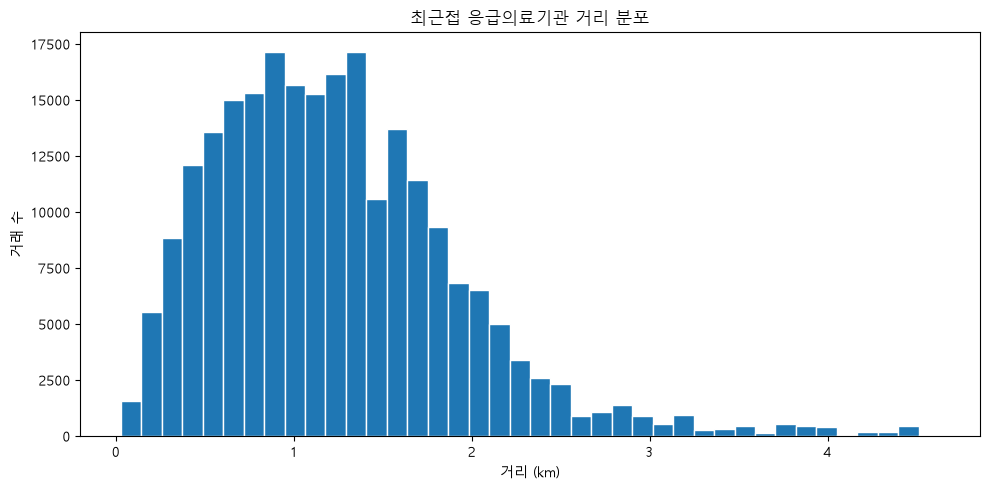

In [159]:
# ============================================================
# 응급의료기관 거리 분포
# ============================================================

plt.figure(figsize=(10, 5))

plt.hist(
    df_living["응급의료기관거리_km"],
    bins=40,
    edgecolor="white",
)

plt.title("최근접 응급의료기관 거리 분포")
plt.xlabel("거리 (km)")
plt.ylabel("거래 수")

plt.tight_layout()
plt.show()

In [160]:
# ============================================================
# 최근접 응급의료기관 유형 분포
# ============================================================

nearest_type_count = (
    df_living["최근접응급의료기관분류"]
    .value_counts()
)

nearest_type_ratio = (
    df_living["최근접응급의료기관분류"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

hospital_type_summary = pd.DataFrame({
    "거래수": nearest_type_count,
    "비율(%)": nearest_type_ratio,
})

hospital_type_summary

,거래수,비율(%)
최근접응급의료기관분류,,
지역응급의료센터,78162,33.36
응급실운영신고기관,64865,27.68
지역응급의료기관,64293,27.44
권역응급의료센터,26982,11.52


In [161]:
# ============================================================
# 병원 입지 피처 최종 검증
# ============================================================

hospital_feature_cols = [
    "최근접응급의료기관",
    "최근접응급의료기관분류",
    "응급의료기관거리_m",
    "응급의료기관거리_km",
]

print("병원 피처 결측치:")
print(
    df_living[
        hospital_feature_cols
    ].isna().sum()
)

print("\n응급의료기관 거리 범위:")
print(
    df_living[
        "응급의료기관거리_km"
    ].agg(["min", "median", "mean", "max"])
)

병원 피처 결측치:
최근접응급의료기관      0
최근접응급의료기관분류    0
응급의료기관거리_m     0
응급의료기관거리_km    0
dtype: int64

응급의료기관 거리 범위:
min       0.029376
median    1.164783
mean      1.239971
max       4.626382
Name: 응급의료기관거리_km, dtype: float64


### 응급의료기관 입지 피처 생성 완료

- 서울 응급의료기관 74개 사용
- 병원 ID 기준 중복 제거
- 주소 및 좌표 유효성 검증 완료
- BallTree + Haversine 기반 최근접 응급의료기관 계산
- 전체 거래 234,302건에 대해 결측 없이 매칭 완료
- 모델링 후보 피처: `응급의료기관거리_km`

# 대형마트

In [162]:
# ============================================================
# 대규모점포 원본 데이터 불러오기
# ============================================================

MART_RAW_PATH = (
    EXTERNAL_DIR
    / "large_scale_store.csv"
)

mart_raw = pd.read_csv(
    MART_RAW_PATH,
    encoding="cp949",
)

print("데이터 크기:", mart_raw.shape)

print("\n컬럼:")
print(mart_raw.columns.tolist())

display(mart_raw.head())

데이터 크기: (1051, 26)

컬럼:
['개방자치단체코드', '관리번호', '인허가일자', '인허가취소일자', '영업상태명', '폐업일자', '휴업시작일자', '휴업종료일자', '재개업일자', '소재지면적', '소재지우편번호', '도로명우편번호', '사업장명', '업태구분명', '데이터갱신구분', '데이터갱신시점', '도로명주소', '상세영업상태명', '상세영업상태코드', '영업상태코드', '전화번호', '점포구분명', '좌표정보(X)', '좌표정보(Y)', '지번주소', '최종수정시점']


,개방자치단체코드,관리번호,인허가일자,인허가취소일자,영업상태명,폐업일자,휴업시작일자,휴업종료일자,재개업일자,소재지면적,...,도로명주소,상세영업상태명,상세영업상태코드,영업상태코드,전화번호,점포구분명,좌표정보(X),좌표정보(Y),지번주소,최종수정시점
0,3000000,2008300012907500001,2008-03-05,NaN,폐업,2014-11-26,NaN,NaN,NaN,18776.28,...,NaN,폐업처리,3,3,221713182.0,NaN,201273.887782,452163.292543,서울특별시 종로구 창신동 328번지 18호,2014-11-27 09:20:40
1,3000000,2022300020207500001,2022-06-28,NaN,영업/정상,NaN,NaN,NaN,NaN,297.00,...,"서울특별시 종로구 통일로 246-10, 무악현대아파트 지하 1층 (무악동)",정상영업,1,1,220062678.0,준대규모점포,196467.975088,452566.134030,서울특별시 종로구 무악동 82 무악현대아파트,2025-04-25 11:24:51
2,3000000,1971300007607500003,1971-09-06,NaN,휴업,NaN,NaN,NaN,NaN,6194.00,...,NaN,휴업처리,2,2,222785356.0,NaN,NaN,NaN,서울특별시 종로구 종로3가 175번지 4호,2007-07-21 10:27:56
3,3000000,1987000007607500005,1987-12-07,NaN,휴업,NaN,NaN,NaN,NaN,NaN,...,NaN,휴업처리,2,2,313395465.0,NaN,NaN,NaN,서울특별시 종로구 창신동 766호,2007-07-21 10:27:56
4,3000000,1987300007607500002,1987-10-30,NaN,휴업,NaN,NaN,NaN,NaN,NaN,...,NaN,휴업처리,2,2,222670291.0,NaN,NaN,NaN,호,2007-07-21 10:27:56


In [163]:
# ============================================================
# 대규모점포 데이터 구조 확인
# ============================================================

for keyword in [
    "영업",
    "업태",
    "구분",
    "사업장",
    "주소",
    "좌표",
    "위도",
    "경도",
]:
    matched_cols = [
        col
        for col in mart_raw.columns
        if keyword in col
    ]

    print(
        f"{keyword}:",
        matched_cols,
    )

영업: ['영업상태명', '상세영업상태명', '상세영업상태코드', '영업상태코드']
업태: ['업태구분명']
구분: ['업태구분명', '데이터갱신구분', '점포구분명']
사업장: ['사업장명']
주소: ['도로명주소', '지번주소']
좌표: ['좌표정보(X)', '좌표정보(Y)']
위도: []
경도: []


In [164]:
pd.DataFrame({
    "컬럼명": mart_raw.columns
})

,컬럼명
0,개방자치단체코드
1,관리번호
2,인허가일자
3,인허가취소일자
4,영업상태명
5,폐업일자
6,휴업시작일자
7,휴업종료일자
8,재개업일자
9,소재지면적


In [165]:
# ============================================================
# 대규모점포 주요 분류값 확인
# ============================================================

check_cols = [
    "영업상태명",
    "상세영업상태명",
    "업태구분명",
    "점포구분명",
]

for col in check_cols:
    print(f"\n[{col}]")
    print(mart_raw[col].value_counts(dropna=False))


[영업상태명]
영업상태명
영업/정상             739
폐업                219
휴업                 81
취소/말소/만료/정지/중지     12
Name: count, dtype: int64

[상세영업상태명]
상세영업상태명
정상영업     713
폐업처리     219
휴업처리      81
영업개시전     18
직권취소      12
NaN        8
Name: count, dtype: int64

[업태구분명]
업태구분명
그 밖의 대규모점포    418
구분없음          262
대형마트          114
쇼핑센터           63
시장             63
복합쇼핑몰          57
백화점            37
전문점            34
NaN             3
Name: count, dtype: int64

[점포구분명]
점포구분명
대규모점포     523
준대규모점포    345
NaN       183
Name: count, dtype: int64


In [166]:
# ============================================================
# 서울 소재 점포 확인
# ============================================================

seoul_mask = (
    mart_raw["도로명주소"].str.contains(
        "서울특별시",
        na=False,
    )
    |
    mart_raw["지번주소"].str.contains(
        "서울특별시",
        na=False,
    )
)

print("전체 점포 수:", len(mart_raw))
print("서울 소재 점포 수:", seoul_mask.sum())

display(
    mart_raw.loc[
        seoul_mask,
        [
            "사업장명",
            "영업상태명",
            "상세영업상태명",
            "업태구분명",
            "점포구분명",
            "도로명주소",
            "좌표정보(X)",
            "좌표정보(Y)",
        ],
    ].head(20)
)

전체 점포 수: 1051
서울 소재 점포 수: 1046


,사업장명,영업상태명,상세영업상태명,업태구분명,점포구분명,도로명주소,좌표정보(X),좌표정보(Y)
0,크레타 망고 아울렛,폐업,폐업처리,전문점,NaN,NaN,201273.887782,452163.292543
1,GS THE FRESH 무악현대점,영업/정상,정상영업,구분없음,준대규모점포,"서울특별시 종로구 통일로 246-10, 무악현대아파트 지하 1층 (무악동)",196467.975088,452566.134030
2,종로세운상가,휴업,휴업처리,그 밖의 대규모점포,NaN,NaN,NaN,NaN
3,숭인제일아케이트,휴업,휴업처리,그 밖의 대규모점포,NaN,NaN,NaN,NaN
5,동대문종합시장,영업/정상,정상영업,그 밖의 대규모점포,대규모점포,서울특별시 종로구 종로 266 (종로6가),200717.749032,452011.865092
6,동대문종합시장 신관,영업/정상,정상영업,복합쇼핑몰,대규모점포,서울특별시 종로구 종로 272 (종로6가),200647.013251,452054.764928
7,광장주식회사,영업/정상,정상영업,시장,NaN,NaN,199837.414267,451974.128468
8,종로1번지아케이트,영업/정상,정상영업,전문점,대규모점포,서울특별시 종로구 종로 1 (종로1가),197993.904628,452032.958591
9,영풍문고,영업/정상,정상영업,대형마트,NaN,NaN,198351.818737,451921.603026
10,동대문신발도매상가,영업/정상,정상영업,그 밖의 대규모점포,NaN,NaN,NaN,NaN


In [167]:
# ============================================================
# 서울 영업 중 대규모점포 추출
# ============================================================

seoul_mask = (
    mart_raw["도로명주소"].str.contains(
        "서울특별시",
        na=False,
    )
    |
    mart_raw["지번주소"].str.contains(
        "서울특별시",
        na=False,
    )
)

store_clean = mart_raw.loc[
    seoul_mask
    & (mart_raw["영업상태명"] == "영업/정상")
    & (mart_raw["상세영업상태명"] == "정상영업")
    & (mart_raw["점포구분명"] == "대규모점포")
].copy()

store_clean = store_clean.reset_index(drop=True)

print("서울 영업 중 대규모점포 수:", len(store_clean))

print("\n업태 분포:")
print(
    store_clean["업태구분명"]
    .value_counts(dropna=False)
)

서울 영업 중 대규모점포 수: 407

업태 분포:
업태구분명
그 밖의 대규모점포    211
대형마트           48
쇼핑센터           38
복합쇼핑몰          31
시장             27
전문점            25
백화점            25
구분없음            2
Name: count, dtype: int64


In [168]:
# ============================================================
# 업태별 대규모점포 예시 확인
# ============================================================

for store_type in store_clean["업태구분명"].dropna().unique():

    print(f"\n[{store_type}]")

    display(
        store_clean.loc[
            store_clean["업태구분명"] == store_type,
            [
                "사업장명",
                "도로명주소",
                "점포구분명",
            ],
        ].head(10)
    )


[그 밖의 대규모점포]


,사업장명,도로명주소,점포구분명
0,동대문종합시장,서울특별시 종로구 종로 266 (종로6가),대규모점포
3,동대문종합시장D동상가,"서울특별시 종로구 종로 266, 동대문종합시장D동상가 동 (종로6가)",대규모점포
5,효성주얼리시티,"서울특별시 종로구 종로 183 (인의동, 효성주얼리시티)",대규모점포
6,세운스퀘어,서울특별시 종로구 창경궁로 109 (인의동),대규모점포
9,낙원상가,"서울특별시 종로구 삼일대로 428, 낙원상가 506호 (낙원동)",대규모점포
10,낙원상가,"서울특별시 종로구 삼일대로 428, 낙원상가 (낙원동)",대규모점포
12,신설종합시장(주),"서울특별시 종로구 난계로27길 51, 신설종합시장 (숭인동)",대규모점포
13,팀204,서울특별시 중구 마장로 30 (신당동),대규모점포
14,통일상가,"서울특별시 중구 청계천로 260-9 (을지로6가, 통일의류종합상가)",대규모점포
15,진양상가,서울특별시 중구 퇴계로 217 (충무로4가),대규모점포



[복합쇼핑몰]


,사업장명,도로명주소,점포구분명
1,동대문종합시장 신관,서울특별시 종로구 종로 272 (종로6가),대규모점포
7,광장시장,서울특별시 종로구 창경궁로 88 (예지동),대규모점포
40,롯데백화점 본점,서울특별시 중구 남대문로 81 (소공동),대규모점포
71,아이파크몰(I PARK MALL),서울특별시 용산구 한강대로23길 55 (한강로3가),대규모점포
89,파크에비뉴 엔터식스 한양대점,서울특별시 성동구 왕십리로 241 (행당동),대규모점포
98,동서울터미널상가,서울특별시 광진구 강변역로 50 (구의동),대규모점포
111,롯데쇼핑(주) 롯데몰 청량리점,"서울특별시 동대문구 왕산로 200, 청량리역 롯데캐슬 SKY-L65 (전농동)",대규모점포
126,롯데백화점 청량리역사점,서울특별시 동대문구 왕산로 214 (전농동),대규모점포
133,동성타워프라자,서울특별시 중랑구 봉화산로 221 (신내동),대규모점포
135,이노시티,"서울특별시 중랑구 망우로 353-0 (상봉동, 프레미어스 엠코)",대규모점포



[전문점]


...

,사업장명,도로명주소,점포구분명
30,엠플라자(M plaza),"서울특별시 중구 명동8길 27 (명동2가, 엠 플라자)",대규모점포
31,굿모닝시티 쇼핑몰,"서울특별시 중구 장충단로 247 (을지로6가,굿모닝시티쇼핑몰)",대규모점포
36,올레오,서울특별시 중구 마장로1길 22 (신당동),대규모점포
41,던던 동대문점,서울특별시 중구 을지로 264 (을지로6가),대규모점포
42,롯데아울렛 서울역점,서울특별시 중구 한강대로 405 (봉래동2가),대규모점포
43,롯데아울렛 서울역점,서울특별시 중구 한강대로 405 (봉래동2가),대규모점포
56,현대시티타워,서울특별시 중구 장충단로 13-20 (을지로6가),대규모점포
62,에이피엠플레이스,"서울특별시 중구 을지로 276 (을지로7가, apMPLACE)",대규모점포
65,센터포인트 명동,NaN,대규모점포
78,해밀톤 쇼핑몰,서울특별시 용산구 이태원로 179 (이태원동),대규모점포



[백화점]


,사업장명,도로명주소,점포구분명
35,신세계백화점,"서울특별시 중구 소공로 63 (충무로1가,신세계백화점건물)",대규모점포
76,아이파크(I PARK)백화점,서울특별시 용산구 한강대로23길 55 (한강로3가),대규모점포
106,롯데백화점 건대스타시티점,서울특별시 광진구 능동로 92 (자양동),대규모점포
127,롯데쇼핑(주)롯데마트 청량리점,서울특별시 동대문구 왕산로 214 (전농동),대규모점포
142,현대백화점 미아점,"서울특별시 성북구 동소문로 315 (길음동, 현대백화점미아점)",대규모점포
187,건영옴니백화점,NaN,대규모점포
205,현대백화점 신촌점,서울특별시 서대문구 신촌로 83 (창천동),대규모점포
222,현대백화점목동점,서울특별시 양천구 목동동로 257 (목동),대규모점포
223,행복한백화점,서울특별시 양천구 목동동로 309 (목동),대규모점포
234,(주) 이랜드리테일 강서점,서울특별시 강서구 강서로56길 17 (등촌동),대규모점포



[구분없음]


,사업장명,도로명주소,점포구분명
83,한남하이츠상가,"서울특별시 성동구 독서당로 160, 한남하이츠아파트 (옥수동)",대규모점포
279,롯데쇼핑(주) 롯데마트맥스 영등포점,서울특별시 영등포구 영중로 125 (영등포동8가),대규모점포


In [169]:
# ============================================================
# 대규모점포 품질 검증
# ============================================================

print("전체 대규모점포 수:", len(store_clean))

print(
    "사업장명 중복:",
    store_clean["사업장명"]
    .duplicated()
    .sum(),
)

print("\n좌표 결측:")
print(
    store_clean[
        [
            "좌표정보(X)",
            "좌표정보(Y)",
        ]
    ].isna().sum()
)

전체 대규모점포 수: 407
사업장명 중복: 15

좌표 결측:
좌표정보(X)    9
좌표정보(Y)    9
dtype: int64


In [170]:
# ============================================================
# 좌표 숫자형 변환
# ============================================================

store_clean["좌표정보(X)"] = pd.to_numeric(
    store_clean["좌표정보(X)"],
    errors="coerce",
)

store_clean["좌표정보(Y)"] = pd.to_numeric(
    store_clean["좌표정보(Y)"],
    errors="coerce",
)

print(
    store_clean[
        [
            "좌표정보(X)",
            "좌표정보(Y)",
        ]
    ].isna().sum()
)

좌표정보(X)    9
좌표정보(Y)    9
dtype: int64


In [171]:
# ============================================================
# 대규모점포 좌표계 변환
# EPSG:5174 → WGS84(EPSG:4326)
# ============================================================

from pyproj import Transformer

transformer = Transformer.from_crs(
    "EPSG:5174",
    "EPSG:4326",
    always_xy=True,
)

valid_coord = (
    store_clean["좌표정보(X)"].notna()
    & store_clean["좌표정보(Y)"].notna()
)

lon, lat = transformer.transform(
    store_clean.loc[
        valid_coord,
        "좌표정보(X)",
    ].to_numpy(),

    store_clean.loc[
        valid_coord,
        "좌표정보(Y)",
    ].to_numpy(),
)

store_clean.loc[valid_coord, "경도"] = lon
store_clean.loc[valid_coord, "위도"] = lat

In [172]:
# ============================================================
# 변환 좌표 검증
# ============================================================

valid_seoul_coord = (
    store_clean["위도"].between(37.4, 37.8)
    & store_clean["경도"].between(126.7, 127.3)
)

print("전체 점포:", len(store_clean))
print("정상 서울 좌표:", valid_seoul_coord.sum())
print("비정상·결측 좌표:", (~valid_seoul_coord).sum())

display(
    store_clean.loc[
        ~valid_seoul_coord,
        [
            "사업장명",
            "업태구분명",
            "도로명주소",
            "지번주소",
            "좌표정보(X)",
            "좌표정보(Y)",
            "위도",
            "경도",
        ],
    ]
)

전체 점포: 407
정상 서울 좌표: 398
비정상·결측 좌표: 9


,사업장명,업태구분명,도로명주소,지번주소,좌표정보(X),좌표정보(Y),위도,경도
56,현대시티타워,쇼핑센터,서울특별시 중구 장충단로 13-20 (을지로6가),NaN,NaN,NaN,NaN,NaN
154,길음시장,그 밖의 대규모점포,NaN,"서울특별시 성북구 길음동 535번지8호, 535번지26호, 540번지2호",NaN,NaN,NaN,NaN
155,길음시장,그 밖의 대규모점포,NaN,"서울특별시 성북구 길음동 535-8,535-26,540-2,540-7",NaN,NaN,NaN,NaN
171,강북종합시장,그 밖의 대규모점포,서울특별시 강북구 한천로148길 12-43 (수유동),서울특별시 강북구 수유3동 179번지 5호,NaN,NaN,NaN,NaN
217,홈플러스(주)월드컵점,대형마트,"서울특별시 마포구 월드컵로 240 (성산동,월드컵경기장내)",서울특별시 마포구 성산동 515호 월드컵경기장내,NaN,NaN,NaN,NaN
228,(주)공항시장,시장,NaN,서울특별시 강서구 방화동 620호,NaN,NaN,NaN,NaN
236,화곡 더리브스카이,그 밖의 대규모점포,"서울특별시 강서구 가로공원로80길 40 (화곡동, 화곡 더리브 스카이)",서울특별시 강서구 화곡동 1175 화곡 더리브 스카이,NaN,NaN,NaN,NaN
274,포레나당산동역세권청년주택 상업시설,그 밖의 대규모점포,"서울특별시 영등포구 당산로 83 (당산동2가, 한화포레나당산)",서울특별시 영등포구 당산동2가 165 한화포레나당산,NaN,NaN,NaN,NaN
322,대림상가,그 밖의 대규모점포,서울특별시 서초구 나루터로 32 (잠원동),NaN,NaN,NaN,NaN,NaN


In [173]:
# ============================================================
# 비정상·결측 좌표 대규모점포 확인
# ============================================================

invalid_store = store_clean.loc[
    ~valid_seoul_coord,
    [
        "사업장명",
        "업태구분명",
        "도로명주소",
        "지번주소",
        "좌표정보(X)",
        "좌표정보(Y)",
        "위도",
        "경도",
    ],
].copy()

print("확인 대상:", len(invalid_store))

display(invalid_store)

확인 대상: 9


,사업장명,업태구분명,도로명주소,지번주소,좌표정보(X),좌표정보(Y),위도,경도
56,현대시티타워,쇼핑센터,서울특별시 중구 장충단로 13-20 (을지로6가),NaN,NaN,NaN,NaN,NaN
154,길음시장,그 밖의 대규모점포,NaN,"서울특별시 성북구 길음동 535번지8호, 535번지26호, 540번지2호",NaN,NaN,NaN,NaN
155,길음시장,그 밖의 대규모점포,NaN,"서울특별시 성북구 길음동 535-8,535-26,540-2,540-7",NaN,NaN,NaN,NaN
171,강북종합시장,그 밖의 대규모점포,서울특별시 강북구 한천로148길 12-43 (수유동),서울특별시 강북구 수유3동 179번지 5호,NaN,NaN,NaN,NaN
217,홈플러스(주)월드컵점,대형마트,"서울특별시 마포구 월드컵로 240 (성산동,월드컵경기장내)",서울특별시 마포구 성산동 515호 월드컵경기장내,NaN,NaN,NaN,NaN
228,(주)공항시장,시장,NaN,서울특별시 강서구 방화동 620호,NaN,NaN,NaN,NaN
236,화곡 더리브스카이,그 밖의 대규모점포,"서울특별시 강서구 가로공원로80길 40 (화곡동, 화곡 더리브 스카이)",서울특별시 강서구 화곡동 1175 화곡 더리브 스카이,NaN,NaN,NaN,NaN
274,포레나당산동역세권청년주택 상업시설,그 밖의 대규모점포,"서울특별시 영등포구 당산로 83 (당산동2가, 한화포레나당산)",서울특별시 영등포구 당산동2가 165 한화포레나당산,NaN,NaN,NaN,NaN
322,대림상가,그 밖의 대규모점포,서울특별시 서초구 나루터로 32 (잠원동),NaN,NaN,NaN,NaN,NaN


In [174]:
# ============================================================
# 주소 기반 좌표 보완 함수
# ============================================================

import requests


def geocode_address(address, kakao_api_key):
    url = "https://dapi.kakao.com/v2/local/search/address.json"

    headers = {
        "Authorization": f"KakaoAK {kakao_api_key}",
    }

    params = {
        "query": address,
    }

    response = requests.get(
        url,
        headers=headers,
        params=params,
        timeout=10,
    )

    response.raise_for_status()

    documents = response.json().get("documents", [])

    if not documents:
        return None, None

    result = documents[0]

    return (
        float(result["y"]),  # 위도
        float(result["x"]),  # 경도
    )

In [175]:
# ============================================================
# 비정상·결측 좌표 지오코딩 보완
# ============================================================

invalid_idx = store_clean.index[
    ~valid_seoul_coord
]

for idx in invalid_idx:
    address = store_clean.loc[idx, "도로명주소"]

    if pd.isna(address):
        address = store_clean.loc[idx, "지번주소"]

    lat, lon = geocode_address(
        address,
        KAKAO_REST_API_KEY,
    )

    store_clean.loc[idx, "위도"] = lat
    store_clean.loc[idx, "경도"] = lon

In [176]:
# ============================================================
# 좌표 보완 결과 검증
# ============================================================

valid_seoul_coord = (
    store_clean["위도"].between(37.4, 37.8)
    & store_clean["경도"].between(126.7, 127.3)
)

print("전체 점포:", len(store_clean))
print("정상 서울 좌표:", valid_seoul_coord.sum())
print("비정상·결측 좌표:", (~valid_seoul_coord).sum())

display(
    store_clean.loc[
        ~valid_seoul_coord,
        [
            "사업장명",
            "도로명주소",
            "지번주소",
            "위도",
            "경도",
        ],
    ]
)

전체 점포: 407
정상 서울 좌표: 401
비정상·결측 좌표: 6


,사업장명,도로명주소,지번주소,위도,경도
56,현대시티타워,서울특별시 중구 장충단로 13-20 (을지로6가),NaN,NaN,NaN
154,길음시장,NaN,"서울특별시 성북구 길음동 535번지8호, 535번지26호, 540번지2호",NaN,NaN
155,길음시장,NaN,"서울특별시 성북구 길음동 535-8,535-26,540-2,540-7",NaN,NaN
171,강북종합시장,서울특별시 강북구 한천로148길 12-43 (수유동),서울특별시 강북구 수유3동 179번지 5호,NaN,NaN
228,(주)공항시장,NaN,서울특별시 강서구 방화동 620호,NaN,NaN
322,대림상가,서울특별시 서초구 나루터로 32 (잠원동),NaN,NaN,NaN


In [177]:
# ============================================================
# 좌표 미확보 대규모점포 상태 확인
# ============================================================

remaining_idx = store_clean.index[
    ~valid_seoul_coord
]

check_cols = [
    "사업장명",
    "업태구분명",
    "영업상태명",
    "상세영업상태명",
    "도로명주소",
    "지번주소",
]

# 날짜 관련 컬럼도 있으면 함께 확인
date_cols = [
    col for col in store_clean.columns
    if any(
        keyword in col
        for keyword in [
            "인허가",
            "개업",
            "폐업",
            "휴업",
            "갱신",
        ]
    )
]

display(
    store_clean.loc[
        remaining_idx,
        check_cols + date_cols,
    ]
)

,사업장명,업태구분명,영업상태명,상세영업상태명,도로명주소,지번주소,인허가일자,인허가취소일자,폐업일자,휴업시작일자,휴업종료일자,재개업일자,데이터갱신구분,데이터갱신시점
56,현대시티타워,쇼핑센터,영업/정상,정상영업,서울특별시 중구 장충단로 13-20 (을지로6가),NaN,1996-08-31,NaN,NaN,NaN,NaN,NaN,I,2026-03-26 22:48:23
154,길음시장,그 밖의 대규모점포,영업/정상,정상영업,NaN,"서울특별시 성북구 길음동 535번지8호, 535번지26호, 540번지2호",2019-05-29,NaN,NaN,NaN,NaN,NaN,I,2025-12-15 16:15:28
155,길음시장,그 밖의 대규모점포,영업/정상,정상영업,NaN,"서울특별시 성북구 길음동 535-8,535-26,540-2,540-7",2019-06-13,NaN,NaN,NaN,NaN,NaN,I,2025-12-15 16:15:28
171,강북종합시장,그 밖의 대규모점포,영업/정상,정상영업,서울특별시 강북구 한천로148길 12-43 (수유동),서울특별시 강북구 수유3동 179번지 5호,2011-01-03,NaN,NaN,NaN,NaN,NaN,I,2026-04-30 22:35:18
228,(주)공항시장,시장,영업/정상,정상영업,NaN,서울특별시 강서구 방화동 620호,1970-08-20,NaN,NaN,NaN,NaN,NaN,I,2025-12-15 16:15:28
322,대림상가,그 밖의 대규모점포,영업/정상,정상영업,서울특별시 서초구 나루터로 32 (잠원동),NaN,1979-12-12,NaN,NaN,NaN,NaN,NaN,I,2025-12-15 16:15:28


In [178]:
# ============================================================
# 동일 사업장명 중복 확인
# ============================================================

duplicate_names = (
    store_clean[
        store_clean["사업장명"].duplicated(
            keep=False
        )
    ]
    .sort_values("사업장명")
)

print(
    "중복 사업장명 행 수:",
    len(duplicate_names),
)

print(
    "중복 사업장명 종류:",
    duplicate_names["사업장명"].nunique(),
)

display(
    duplicate_names[
        [
            "사업장명",
            "업태구분명",
            "도로명주소",
            "지번주소",
            "인허가일자",
            "위도",
            "경도",
        ]
    ]
)

중복 사업장명 행 수: 28
중복 사업장명 종류: 13


,사업장명,업태구분명,도로명주소,지번주소,인허가일자,위도,경도
211,(주)이마트 마포점,대형마트,서울특별시 마포구 백범로 212 (신공덕동),서울특별시 마포구 공덕동 173번지 대우월드마크마포,2010-12-23,37.542444,126.953365
210,(주)이마트 마포점,대형마트,서울특별시 마포구 백범로 212 (신공덕동),서울특별시 마포구 신공덕동 173번지,2010-12-23,37.542444,126.953365
258,고척산업용품상가,그 밖의 대규모점포,"서울특별시 구로구 중앙로3길 50 (고척동, 고척산업용품종합상가)",서울특별시 구로구 고척동 103번지 4호,1986-11-01,37.499809,126.860781
249,고척산업용품상가,복합쇼핑몰,"서울특별시 구로구 경인로43길 42 (고척동, 고척산업용품상가)",서울특별시 구로구 고척동 103번지 4호,1986-11-01,37.499809,126.860781
143,길음시장,시장,서울특별시 성북구 동소문로 227 (길음동),서울특별시 성북구 길음동 535번지 8호,2003-02-10,37.602712,127.021767
155,길음시장,그 밖의 대규모점포,NaN,"서울특별시 성북구 길음동 535-8,535-26,540-2,540-7",2019-06-13,NaN,NaN
154,길음시장,그 밖의 대규모점포,NaN,"서울특별시 성북구 길음동 535번지8호, 535번지26호, 540번지2호",2019-05-29,NaN,NaN
9,낙원상가,그 밖의 대규모점포,"서울특별시 종로구 삼일대로 428, 낙원상가 506호 (낙원동)",서울특별시 종로구 낙원동 288번지 낙원상가,2019-09-17,37.572217,126.987645
10,낙원상가,그 밖의 대규모점포,"서울특별시 종로구 삼일대로 428, 낙원상가 (낙원동)",서울특별시 종로구 낙원동 288번지 낙원상가,2019-09-17,37.572217,126.987645
34,대림상가,그 밖의 대규모점포,서울특별시 중구 을지로 157 (을지로4가),서울특별시 중구 을지로4가 9번지 6호,1972-09-18,37.566758,126.995517


In [179]:
# ============================================================
# 지오코딩용 주소 정리
# ============================================================

def simplify_address(address):
    if pd.isna(address):
        return None

    address = str(address).strip()

    # 괄호 이하 제거
    address = address.split("(")[0].strip()

    # 여러 필지가 쉼표로 연결된 경우 첫 번째 주소만 사용
    address = address.split(",")[0].strip()

    return address

In [180]:
for idx in store_clean.index[
    ~valid_seoul_coord
]:
    print(
        store_clean.loc[idx, "사업장명"],
        "→",
        simplify_address(
            store_clean.loc[idx, "지번주소"]
        ),
    )

현대시티타워 → None
길음시장 → 서울특별시 성북구 길음동 535번지8호
길음시장 → 서울특별시 성북구 길음동 535-8
강북종합시장 → 서울특별시 강북구 수유3동 179번지 5호
(주)공항시장 → 서울특별시 강서구 방화동 620호
대림상가 → None


In [181]:
# ============================================================
# 동일 위치 대규모점포 중복 제거
# ============================================================

before_rows = len(store_clean)

store_clean = (
    store_clean
    .sort_values(
        "데이터갱신시점",
        ascending=False,
    )
    .drop_duplicates(
        subset=[
            "사업장명",
            "위도",
            "경도",
        ],
        keep="first",
    )
    .reset_index(drop=True)
)

print("중복 제거 전:", before_rows)
print("중복 제거 후:", len(store_clean))

중복 제거 전: 407
중복 제거 후: 395


In [182]:
# ============================================================
# 자치구 추출
# ============================================================

address = (
    store_clean["도로명주소"]
    .fillna(store_clean["지번주소"])
)

store_clean["자치구"] = address.str.extract(
    r"서울특별시\s+(\S+구)"
)

In [183]:
names_with_valid_coord = (
    store_clean.loc[
        store_clean["위도"].notna()
        & store_clean["경도"].notna(),
        ["사업장명", "자치구"],
    ]
    .drop_duplicates()
)

store_clean = store_clean.merge(
    names_with_valid_coord.assign(
        동일시설_정상좌표존재=True
    ),
    on=[
        "사업장명",
        "자치구",
    ],
    how="left",
)

remove_mask = (
    store_clean["동일시설_정상좌표존재"].eq(True)
    & (
        store_clean["위도"].isna()
        | store_clean["경도"].isna()
    )
)

store_clean = (
    store_clean.loc[~remove_mask]
    .drop(columns="동일시설_정상좌표존재")
    .reset_index(drop=True)
)

In [184]:
# ============================================================
# 동일 사업장명 중복 후보 거리 계산
# ============================================================

from itertools import combinations
import numpy as np
import pandas as pd


def haversine_distance(
    lat1,
    lon1,
    lat2,
    lon2,
):
    earth_radius_m = 6_371_000

    lat1, lon1, lat2, lon2 = map(
        np.radians,
        [lat1, lon1, lat2, lon2],
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return (
        2
        * earth_radius_m
        * np.arcsin(np.sqrt(a))
    )


duplicate_pairs = []

for store_name, group in store_clean.groupby("사업장명"):

    if len(group) < 2:
        continue

    valid_group = group.dropna(
        subset=["위도", "경도"]
    )

    for idx1, idx2 in combinations(
        valid_group.index,
        2,
    ):
        row1 = store_clean.loc[idx1]
        row2 = store_clean.loc[idx2]

        distance = haversine_distance(
            row1["위도"],
            row1["경도"],
            row2["위도"],
            row2["경도"],
        )

        duplicate_pairs.append({
            "사업장명": store_name,
            "index_1": idx1,
            "index_2": idx2,
            "거리_m": distance,
            "주소_1": row1["도로명주소"],
            "주소_2": row2["도로명주소"],
        })


duplicate_check = pd.DataFrame(
    duplicate_pairs
).sort_values("거리_m")

duplicate_check

,사업장명,index_1,index_2,거리_m,주소_1,주소_2
0,통일상가,194,210,89.91769,서울특별시 중구 장충단로13길 20 (을지로6가),"서울특별시 중구 청계천로 260-9 (을지로6가, 통일의류종합상가)"


In [185]:
# ============================================================
# 중복 후보 자동 분류
# ============================================================

duplicate_check["판정"] = np.select(
    [
        duplicate_check["거리_m"] <= 50,
        duplicate_check["거리_m"] <= 200,
    ],
    [
        "동일시설_가능성높음",
        "수동확인필요",
    ],
    default="다른시설_가능성높음",
)

display(
    duplicate_check[
        [
            "사업장명",
            "거리_m",
            "판정",
            "주소_1",
            "주소_2",
        ]
    ]
)

,사업장명,거리_m,판정,주소_1,주소_2
0,통일상가,89.91769,수동확인필요,서울특별시 중구 장충단로13길 20 (을지로6가),"서울특별시 중구 청계천로 260-9 (을지로6가, 통일의류종합상가)"


In [186]:
# ============================================================
# 통일상가 주소 오류 레코드 제거
# ============================================================

wrong_tongil_mask = (
    (store_clean["사업장명"] == "통일상가")
    & store_clean["도로명주소"].str.contains(
        "장충단로13길 20",
        na=False,
    )
)

display(
    store_clean.loc[
        wrong_tongil_mask,
        [
            "사업장명",
            "도로명주소",
            "지번주소",
            "위도",
            "경도",
        ],
    ]
)

store_clean = (
    store_clean.loc[~wrong_tongil_mask]
    .reset_index(drop=True)
)

print("제거 후 점포 수:", len(store_clean))

,사업장명,도로명주소,지번주소,위도,경도
194,통일상가,서울특별시 중구 장충단로13길 20 (을지로6가),서울특별시 중구 을지로6가 17번지,37.568643,127.007732


제거 후 점포 수: 393


In [187]:
store_clean.loc[
    store_clean["사업장명"] == "통일상가",
    [
        "사업장명",
        "도로명주소",
        "위도",
        "경도",
    ],
]

,사업장명,도로명주소,위도,경도
209,통일상가,"서울특별시 중구 청계천로 260-9 (을지로6가, 통일의류종합상가)",37.568956,127.006791


In [188]:
# ============================================================
# 대규모점포 최종 품질 검증
# ============================================================

valid_store_coord = (
    store_clean["위도"].between(37.4, 37.8)
    & store_clean["경도"].between(126.7, 127.3)
)

print("최종 점포 수:", len(store_clean))
print("정상 서울 좌표:", valid_store_coord.sum())
print("비정상·결측 좌표:", (~valid_store_coord).sum())

print(
    "\n동일 사업장명 중복:",
    store_clean["사업장명"]
    .duplicated()
    .sum(),
)

최종 점포 수: 393
정상 서울 좌표: 389
비정상·결측 좌표: 4

동일 사업장명 중복: 1


In [189]:
# ============================================================
# 거리 계산용 대규모점포 데이터
# ============================================================

store_valid = (
    store_clean.loc[
        valid_store_coord,
        [
            "사업장명",
            "업태구분명",
            "도로명주소",
            "지번주소",
            "위도",
            "경도",
        ],
    ]
    .reset_index(drop=True)
)

print("거리 계산 사용 점포 수:", len(store_valid))

거리 계산 사용 점포 수: 389


In [190]:
# ============================================================
# 최근접 대규모점포 계산
# ============================================================

apt_mask = (
    df_living["위도"].notna()
    & df_living["경도"].notna()
)

nearest_idx, nearest_distance = get_nearest_facility(
    df_living.loc[
        apt_mask,
        "위도",
    ].to_numpy(),

    df_living.loc[
        apt_mask,
        "경도",
    ].to_numpy(),

    store_valid["위도"].to_numpy(),
    store_valid["경도"].to_numpy(),
)

In [191]:
# ============================================================
# 대규모점포 입지 피처 추가
# ============================================================

nearest_stores = (
    store_valid
    .iloc[nearest_idx]
    .reset_index(drop=True)
)

df_living.loc[
    apt_mask,
    "최근접대규모점포"
] = nearest_stores[
    "사업장명"
].to_numpy()

df_living.loc[
    apt_mask,
    "최근접대규모점포업태"
] = nearest_stores[
    "업태구분명"
].to_numpy()

df_living.loc[
    apt_mask,
    "대규모점포거리_m"
] = nearest_distance

df_living["대규모점포거리_km"] = (
    df_living["대규모점포거리_m"] / 1000
)

In [192]:
# ============================================================
# 대규모점포 피처 검증
# ============================================================

store_feature_cols = [
    "최근접대규모점포",
    "최근접대규모점포업태",
    "대규모점포거리_m",
    "대규모점포거리_km",
]

print("결측치:")
print(
    df_living[
        store_feature_cols
    ].isna().sum()
)

print("\n거리 통계:")
print(
    df_living[
        "대규모점포거리_m"
    ].describe()
)

결측치:
최근접대규모점포      0
최근접대규모점포업태    0
대규모점포거리_m     0
대규모점포거리_km    0
dtype: int64

거리 통계:
count    234302.000000
mean        621.320157
std         400.834006
min           0.000876
25%         343.740584
50%         548.411061
75%         833.438035
max        3492.928165
Name: 대규모점포거리_m, dtype: float64


In [193]:
# ============================================================
# 최종 좌표 미확보 점포 확인
# ============================================================

display(
    store_clean.loc[
        ~valid_store_coord,
        [
            "사업장명",
            "업태구분명",
            "도로명주소",
            "지번주소",
            "인허가일자",
            "위도",
            "경도",
        ],
    ]
)

,사업장명,업태구분명,도로명주소,지번주소,인허가일자,위도,경도
142,강북종합시장,그 밖의 대규모점포,서울특별시 강북구 한천로148길 12-43 (수유동),서울특별시 강북구 수유3동 179번지 5호,2011-01-03,NaN,NaN
175,현대시티타워,쇼핑센터,서울특별시 중구 장충단로 13-20 (을지로6가),NaN,1996-08-31,NaN,NaN
244,대림상가,그 밖의 대규모점포,서울특별시 서초구 나루터로 32 (잠원동),NaN,1979-12-12,NaN,NaN
344,(주)공항시장,시장,NaN,서울특별시 강서구 방화동 620호,1970-08-20,NaN,NaN


In [194]:
# ============================================================
# 남은 동일 사업장명 확인
# ============================================================

duplicate_store = store_clean.loc[
    store_clean["사업장명"].duplicated(
        keep=False
    ),
    [
        "사업장명",
        "업태구분명",
        "도로명주소",
        "지번주소",
        "위도",
        "경도",
    ],
].sort_values("사업장명")

display(duplicate_store)

,사업장명,업태구분명,도로명주소,지번주소,위도,경도
191,대림상가,그 밖의 대규모점포,서울특별시 중구 을지로 157 (을지로4가),서울특별시 중구 을지로4가 9번지 6호,37.566758,126.995517
244,대림상가,그 밖의 대규모점포,서울특별시 서초구 나루터로 32 (잠원동),NaN,NaN,NaN


In [195]:
store_valid = (
    store_clean.loc[
        valid_store_coord
    ]
    .reset_index(drop=True)
)

In [196]:
# ============================================================
# 현재 생활입지로 보기 어려운 공항시장 제외
# ============================================================

airport_market_mask = (
    store_clean["사업장명"] == "(주)공항시장"
)

display(
    store_clean.loc[
        airport_market_mask,
        [
            "사업장명",
            "업태구분명",
            "도로명주소",
            "지번주소",
        ],
    ]
)

store_clean = (
    store_clean.loc[~airport_market_mask]
    .reset_index(drop=True)
)

print("제거 후 점포 수:", len(store_clean))

,사업장명,업태구분명,도로명주소,지번주소
344,(주)공항시장,시장,NaN,서울특별시 강서구 방화동 620호


제거 후 점포 수: 392


In [197]:
# ============================================================
# 최종 좌표 보완 대상 확인
# ============================================================

missing_coord_mask = (
    store_clean["위도"].isna()
    | store_clean["경도"].isna()
)

display(
    store_clean.loc[
        missing_coord_mask,
        [
            "사업장명",
            "도로명주소",
            "지번주소",
        ],
    ]
)

print(
    "좌표 보완 대상:",
    missing_coord_mask.sum(),
)

,사업장명,도로명주소,지번주소
142,강북종합시장,서울특별시 강북구 한천로148길 12-43 (수유동),서울특별시 강북구 수유3동 179번지 5호
175,현대시티타워,서울특별시 중구 장충단로 13-20 (을지로6가),NaN
244,대림상가,서울특별시 서초구 나루터로 32 (잠원동),NaN


좌표 보완 대상: 3


In [202]:
# ============================================================
# Kakao 키워드 기반 좌표 검색
# ============================================================

def geocode_keyword(keyword, kakao_api_key):
    url = "https://dapi.kakao.com/v2/local/search/keyword.json"

    headers = {
        "Authorization": f"KakaoAK {kakao_api_key}",
    }

    params = {
        "query": keyword,
    }

    response = requests.get(
        url,
        headers=headers,
        params=params,
        timeout=10,
    )

    if response.status_code != 200:
        return None, None

    documents = response.json().get("documents", [])

    if not documents:
        return None, None

    result = documents[0]

    return (
        float(result["y"]),
        float(result["x"]),
    )

In [204]:
# ============================================================
# 주소 정리 함수
# ============================================================

import re


def clean_address(address):
    if pd.isna(address):
        return None

    address = str(address).strip()

    # 괄호 내용 제거
    address = re.sub(
        r"\([^)]*\)",
        "",
        address,
    )

    # 여러 공백 정리
    address = re.sub(
        r"\s+",
        " ",
        address,
    )

    # 여러 지번이 쉼표로 붙은 경우 첫 번째 주소 사용
    address = address.split(",")[0].strip()

    return address

In [205]:
# ============================================================
# 남은 대규모점포 좌표 보완
# ============================================================

missing_idx = store_clean.index[
    store_clean["위도"].isna()
    | store_clean["경도"].isna()
]

for idx in missing_idx:

    store_name = store_clean.loc[idx, "사업장명"]

    road_address = clean_address(
        store_clean.loc[idx, "도로명주소"]
    )

    jibun_address = clean_address(
        store_clean.loc[idx, "지번주소"]
    )

    lat, lon = None, None

    # 1. 도로명주소
    if road_address:
        lat, lon = geocode_address(
            road_address,
            KAKAO_REST_API_KEY,
        )

    # 2. 지번주소
    if lat is None and jibun_address:
        lat, lon = geocode_address(
            jibun_address,
            KAKAO_REST_API_KEY,
        )

    # 3. 사업장명 검색
    if lat is None:
        lat, lon = geocode_keyword(
            f"서울 {store_name}",
            KAKAO_REST_API_KEY,
        )

    store_clean.loc[idx, "위도"] = lat
    store_clean.loc[idx, "경도"] = lon

In [206]:
print(clean_address("서울특별시 중구 장충단로 13-20 (을지로6가)"))

서울특별시 중구 장충단로 13-20


In [207]:
# ============================================================
# 대규모점포 좌표 최종 검증
# ============================================================

valid_store_coord = (
    store_clean["위도"].between(37.4, 37.8)
    & store_clean["경도"].between(126.7, 127.3)
)

print("전체 점포 수:", len(store_clean))
print("정상 서울 좌표:", valid_store_coord.sum())
print("비정상·결측 좌표:", (~valid_store_coord).sum())

display(
    store_clean.loc[
        ~valid_store_coord,
        [
            "사업장명",
            "도로명주소",
            "지번주소",
            "위도",
            "경도",
        ],
    ]
)

전체 점포 수: 392
정상 서울 좌표: 392
비정상·결측 좌표: 0


,사업장명,도로명주소,지번주소,위도,경도


In [208]:
# ============================================================
# 거리 계산용 대규모점포 확정
# ============================================================

store_valid = (
    store_clean.loc[
        valid_store_coord,
        [
            "사업장명",
            "업태구분명",
            "위도",
            "경도",
        ],
    ]
    .reset_index(drop=True)
)

print("최종 사용 대규모점포 수:", len(store_valid))

최종 사용 대규모점포 수: 392


In [209]:
# ============================================================
# 최근접 대규모점포 계산
# ============================================================

apt_mask = (
    df_living["위도"].notna()
    & df_living["경도"].notna()
)

nearest_idx, nearest_distance = get_nearest_facility(
    df_living.loc[apt_mask, "위도"].to_numpy(),
    df_living.loc[apt_mask, "경도"].to_numpy(),
    store_valid["위도"].to_numpy(),
    store_valid["경도"].to_numpy(),
)

nearest_stores = (
    store_valid
    .iloc[nearest_idx]
    .reset_index(drop=True)
)

df_living.loc[
    apt_mask,
    "최근접대규모점포"
] = nearest_stores["사업장명"].to_numpy()

df_living.loc[
    apt_mask,
    "최근접대규모점포업태"
] = nearest_stores["업태구분명"].to_numpy()

df_living.loc[
    apt_mask,
    "대규모점포거리_m"
] = nearest_distance

df_living["대규모점포거리_km"] = (
    df_living["대규모점포거리_m"] / 1000
)

In [210]:
# ============================================================
# 대규모점포 피처 최종 검증
# ============================================================

store_feature_cols = [
    "최근접대규모점포",
    "최근접대규모점포업태",
    "대규모점포거리_m",
    "대규모점포거리_km",
]

print("결측치:")
print(
    df_living[
        store_feature_cols
    ].isna().sum()
)

print("\n거리 통계:")
print(
    df_living[
        "대규모점포거리_m"
    ].describe()
)

결측치:
최근접대규모점포      0
최근접대규모점포업태    0
대규모점포거리_m     0
대규모점포거리_km    0
dtype: int64

거리 통계:
count    234302.000000
mean        621.231356
std         400.890369
min           0.000876
25%         343.740584
50%         548.411061
75%         833.438035
max        3492.928165
Name: 대규모점포거리_m, dtype: float64


In [211]:
# ============================================================
# 대규모점포 초근접 단지 확인
# ============================================================

near_store_check = (
    df_living[
        [
            "법정동",
            "단지명",
            "위도",
            "경도",
            "최근접대규모점포",
            "최근접대규모점포업태",
            "대규모점포거리_m",
        ]
    ]
    .drop_duplicates(
        subset=[
            "법정동",
            "단지명",
            "위도",
            "경도",
        ]
    )
    .sort_values("대규모점포거리_m")
    .head(10)
)

display(near_store_check)

,법정동,단지명,위도,경도,최근접대규모점포,최근접대규모점포업태,대규모점포거리_m
42904,하월곡동,코업스타클래스,37.601821,127.040445,홈플러스 월곡점,대형마트,0.000876
205365,마천동,현대그린빌,37.495183,127.150958,송파쇼핑센타,그 밖의 대규모점포,0.000933
191572,개포동,성원대치2단지아파트,37.494185,127.075215,대치1단지상가,그 밖의 대규모점포,0.001098
191606,개포동,삼익대청아파트,37.494185,127.075215,대치1단지상가,그 밖의 대규모점포,0.001098
204812,잠실동,우성아파트,37.506865,127.073142,프리마 쇼핑센타,그 밖의 대규모점포,0.001251
192516,압구정동,"현대7차(73~77,82,85동)",37.529934,127.028905,금강상가,그 밖의 대규모점포,0.001368
192481,압구정동,"현대6차(78~81,83,84,86,87동)",37.529934,127.028905,금강상가,그 밖의 대규모점포,0.001368
126070,방화동,삼정코아,37.571975,126.811924,삼정프라자,그 밖의 대규모점포,0.001633
9789,행당동,행당한진타운,37.555880,127.029207,한진종합상가,그 밖의 대규모점포,0.001707
23,인의동,효성쥬얼리시티,37.571483,126.998667,효성주얼리시티,그 밖의 대규모점포,0.001813


In [212]:
# ============================================================
# 대규모점포 접근성이 낮은 단지 확인
# ============================================================

far_store_check = (
    df_living[
        [
            "법정동",
            "단지명",
            "위도",
            "경도",
            "최근접대규모점포",
            "최근접대규모점포업태",
            "대규모점포거리_m",
        ]
    ]
    .drop_duplicates(
        subset=[
            "법정동",
            "단지명",
            "위도",
            "경도",
        ]
    )
    .sort_values(
        "대규모점포거리_m",
        ascending=False,
    )
    .head(10)
)

display(far_store_check)

,법정동,단지명,위도,경도,최근접대규모점포,최근접대규모점포업태,대규모점포거리_m
140070,항동,항동제일풍경채포레스트,37.475494,126.816124,개봉제일시장,그 밖의 대규모점포,3492.928165
193,평창동,엘리시아,37.609687,126.975920,동소문스카이상가,그 밖의 대규모점포,3452.641279
150,평창동,롯데낙천대,37.609136,126.975681,동소문스카이상가,그 밖의 대규모점포,3442.329767
427,평창동,크래스빌,37.608520,126.974203,유진상가,시장,3438.306788
22,평창동,벽산블루밍평창힐스,37.608214,126.973756,유진상가,시장,3386.547349
172,평창동,일성빌라트,37.609126,126.972704,유진상가,시장,3370.117395
664,평창동,롯데캐슬로잔,37.609979,126.977400,동소문스카이상가,그 밖의 대규모점포,3354.998914
1930,평창동,형우럭스빌(33-1),37.607541,126.973393,유진상가,시장,3318.167353
57,평창동,삼성,37.610929,126.978673,동소문스카이상가,그 밖의 대규모점포,3314.376578
139388,온수동,두양그린B동,37.495218,126.815769,개봉프라자,시장,3212.637532


In [213]:
# ============================================================
# 초근접 거리 수치 오차 정리
# ============================================================

near_zero_mask = (
    df_living["대규모점포거리_m"] < 1
)

print(
    "1m 미만 거래 건수:",
    near_zero_mask.sum(),
)

df_living.loc[
    near_zero_mask,
    "대규모점포거리_m",
] = 0

df_living["대규모점포거리_km"] = (
    df_living["대규모점포거리_m"] / 1000
)

1m 미만 거래 건수: 5092


In [214]:
# ============================================================
# 대규모점포 입지 피처 최종 확인
# ============================================================

store_feature_cols = [
    "최근접대규모점포",
    "최근접대규모점포업태",
    "대규모점포거리_m",
    "대규모점포거리_km",
]

print("대규모점포 피처 생성 완료")
print("거래 데이터:", len(df_living))
print()

print(
    df_living[
        store_feature_cols
    ].isna().sum()
)

대규모점포 피처 생성 완료
거래 데이터: 234302

최근접대규모점포      0
최근접대규모점포업태    0
대규모점포거리_m     0
대규모점포거리_km    0
dtype: int64
